# 02. 발행량과 금리의 관계 (회귀분석)

**질문:** 금리가 바뀌면 스테이블코인 시장(=발행사의 준비금 R)은 얼마나 변하나?
이 답(계수 b1)이 6단계 시뮬레이션에서 "금리가 떨어질 때 R이 같이 늘어나 손실을 일부 메워 주는가"를 정한다.

**이번 분석에서 정한 것**

| 항목 | 결정 |
|---|---|
| 기간 | 2020년 5월 ~ 2026년 9월 (월간). 2026년 10월은 월말 전이라 제외 |
| 종속변수(설명하고 싶은 것) | **USDC를 뺀** 스테이블코인 시장의 월간 로그 변화율. 전체 시장은 확인용 |
| 금리 | **2년물 국채금리 변화(%p)**. 기준금리·금리 수준은 확인용 |
| 통제 변수 | 비트코인 월간 로그 변화율, 시장 전체 충격 더미(`event_market`) |
| USDC 점유율 | 회귀하지 않음 |

**메인 회귀식**

$$\Delta\log(\text{USDC 제외 시장})_t = a + b_1\,\Delta(\text{2년물})_t + b_2\,\Delta\log(\text{비트코인})_t + b_3\,\text{event\_market}_t + \varepsilon_t$$

- **회귀분석**: 여러 요인이 결과에 각각 얼마나 영향을 주는지, 데이터에 가장 잘 맞는 직선(평면)을 찾아 숫자로 뽑는 방법.
- **b1이 가장 중요하다.** "2년물 금리가 한 달에 1%p 오르면, 그 달 시장이 몇 % 변하나"를 뜻한다.
- **USDC를 뺀 시장을 쓰는 이유**: 전체 시장 안에 USDC가 약 24% 들어 있어서, 전체 시장을 쓰면 USDC 고유 사건(SVB 등)이 섞인다. USDC를 빼면 "금리가 스테이블코인 수요 전반에 주는 영향"을 더 깨끗하게 볼 수 있다.

## 1. 준비

### 라이브러리 불러오기
이 셀이 하는 일: 이번 노트북에서 쓸 도구를 불러온다.
- `numpy`: 로그 같은 수학 계산 도구
- `statsmodels`: 회귀분석 도구

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import acf   # 자기상관 계산용 (5번에서 설명)

### 경로와 그래프 설정
이 셀이 하는 일: 폴더 경로를 정하고, 01번 노트북과 같은 그래프 설정(한글 폰트)을 불러온다.

In [2]:
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = PROJECT / "data" / "processed"
FIG_DIR = PROJECT / "output" / "figures"
sys.path.append(str(PROJECT))

from src.plot_style import setup_plot_style, COLORS, MUTED, TEXT_SUB, SHADE
setup_plot_style()

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")   # 표의 숫자를 소수 넷째 자리까지

## 2. 데이터 불러오기
이 셀이 하는 일: 01번 노트북에서 만든 **월간** 데이터를 읽고, 2026년 9월까지만 남긴다.
- 월간 데이터의 유통량·시장·비트코인은 **월말 값**, 금리는 **월평균**이다. (01번 노트북 2-10)

In [3]:
monthly = pd.read_parquet(PROC_DIR / "usdc_rates_monthly.parquet")
monthly = monthly.loc[:"2026-09-30"]   # 2026년 10월(26일까지만 있음) 제외

print("기간:", monthly.index[0].date(), "~", monthly.index[-1].date(), "|", len(monthly), "개월")
monthly.tail(3)

기간: 2020-01-31 ~ 2026-09-30 | 81 개월


,usdc_bn,usdt_bn,stable_total_bn,usdc_share,btc_usd,base_rate,dgs2,event_market,event_usdc,event_regulation,data_flag
date,,,,,,,,,,,
2026-07-31,72.0554,183.4535,299.0603,24.0939,"62,886.6400",3.6161,4.2181,0,0,0,False
2026-08-31,74.0654,183.4957,302.4743,24.4865,"78,603.0200",3.6413,4.2252,0,0,0,False
2026-09-30,74.5835,183.8399,306.6731,24.3202,"83,482.5100",3.7487,4.6397,0,0,0,False


## 3. 변수 만들기

### 로그 변화율과 %p 변화
- **로그 변화율** Δlog(X) = log(이번 달) − log(지난달). 변화가 작을 때는 **% 변화율과 거의 같다.** (예: 0.05 ≈ 5% 증가)
  - 로그를 쓰는 이유: 시장 규모가 50억 달러일 때와 3,000억 달러일 때의 "10억 달러 증가"는 의미가 다르다. 비율로 보면 같은 기준으로 비교할 수 있다.
- **금리 변화** Δ(2년물) = 이번 달 평균 − 지난달 평균 (단위: **%p**, 퍼센트포인트). 예: 4.0% → 4.25%는 +0.25%p.

이 셀이 하는 일: 회귀에 쓸 변수들을 만들어 `data` 표에 담는다. 강건성 검정용 변수(전체 시장, 기준금리, 금리 수준, 앞뒤 시차)도 함께 만든다.
- **시차**: `shift(1)`은 한 칸 아래로 밀기 = **한 달 전** 값. `shift(-1)`은 한 칸 위로 = **한 달 뒤** 값.

In [4]:
data = pd.DataFrame(index=monthly.index)

# 종속변수
data["y_ex_usdc"] = np.log(monthly["stable_total_bn"] - monthly["usdc_bn"]).diff()   # 메인: USDC 제외 시장
data["y_total"]   = np.log(monthly["stable_total_bn"]).diff()                         # 확인용: 전체 시장

# 금리
data["d_dgs2"]    = monthly["dgs2"].diff()        # 메인: 2년물 변화 (%p)
data["d_base"]    = monthly["base_rate"].diff()   # 확인용: 기준금리 변화
data["dgs2_level"] = monthly["dgs2"]              # 확인용: 2년물 수준 (%)
for k in [1, 2]:
    data[f"d_dgs2_lag{k}"]  = data["d_dgs2"].shift(k)    # k개월 전 금리 변화
    data[f"d_dgs2_lead{k}"] = data["d_dgs2"].shift(-k)   # k개월 뒤 금리 변화

# 통제 변수
data["d_log_btc"]    = np.log(monthly["btc_usd"]).diff()
data["event_market"] = monthly["event_market"]

data = data.loc["2020-05":]   # 시작: 2020년 5월 (2020년 1·4월 USDT 계단 제외)
print("관측치:", len(data), "개월 |", data.index[0].date(), "~", data.index[-1].date())
data[["y_ex_usdc", "d_dgs2", "d_log_btc", "event_market"]].describe().T[["count", "mean", "std", "min", "max"]]

관측치: 77 개월 | 2020-05-31 ~ 2026-09-30


,count,mean,std,min,max
y_ex_usdc,77.0000,0.0431,0.0742,-0.1252,0.2967
d_dgs2,77.0000,0.0574,0.2217,-0.5319,0.6397
d_log_btc,77.0000,0.0294,0.1723,-0.4720,0.3862
event_market,77.0000,0.0260,0.1601,0.0000,1.0000


**읽는 법**
- `y_ex_usdc` 평균 약 0.043 = USDC 제외 시장이 **한 달 평균 약 4.3%** 커졌다. 2020~21년 급성장기가 평균을 끌어올렸다.
- `d_dgs2` 표준편차 약 0.22 = 2년물은 한 달에 보통 **±0.2%p** 정도 움직인다. 1%p는 아주 큰 움직임이라는 점을 기억하자.

## 4. 회귀 전에 눈으로 보기
이 셀이 하는 일: 가로축에 2년물 변화, 세로축에 USDC 제외 시장 변화율을 찍는다(점 하나 = 한 달). 시장 전체 충격이 있었던 달은 다른 색으로 표시한다.
- 점들이 **오른쪽 아래로** 기울어 있으면 "금리가 오른 달에 시장이 덜 컸다"는 뜻이다.

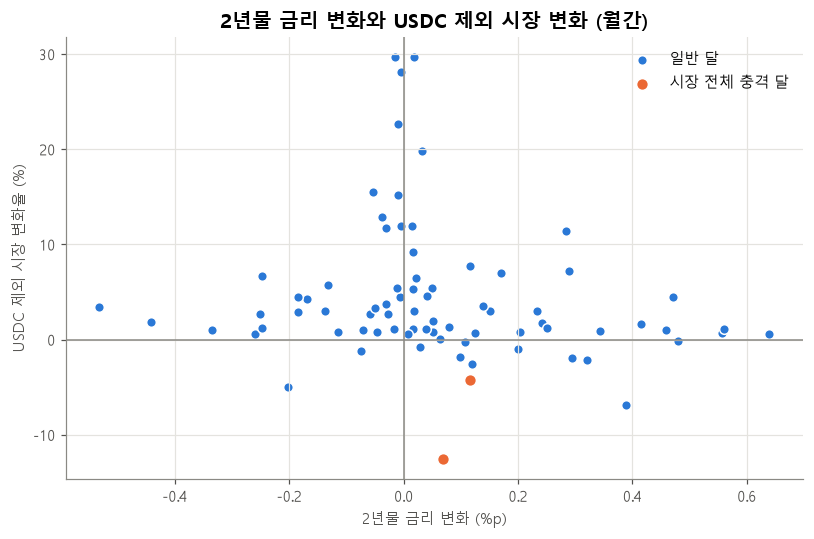

In [5]:
is_event = data["event_market"] == 1

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(data.loc[~is_event, "d_dgs2"], data.loc[~is_event, "y_ex_usdc"] * 100,
           s=40, color=COLORS[0], edgecolor="white", linewidth=1, label="일반 달")
ax.scatter(data.loc[is_event, "d_dgs2"], data.loc[is_event, "y_ex_usdc"] * 100,
           s=60, color=COLORS[1], edgecolor="white", linewidth=1, label="시장 전체 충격 달")
ax.axhline(0, color=MUTED, linewidth=1)
ax.axvline(0, color=MUTED, linewidth=1)

ax.set_title("2년물 금리 변화와 USDC 제외 시장 변화 (월간)")
ax.set_xlabel("2년물 금리 변화 (%p)")
ax.set_ylabel("USDC 제외 시장 변화율 (%)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "3_scatter_dgs2_market.png", dpi=200)
plt.show()

**읽는 법**: 2년물이 거의 안 움직인 달(가로 0 근처)에 시장 성장률이 크게 흩어져 있다. 이건 대부분 2020~21년 급성장기다. 금리가 크게 움직인 달만 보면 약하게 오른쪽 아래로 기운 모양이다.

## 5. 왜 Newey-West 표준오차를 쓰나

**표준오차**: 추정값(b1)이 데이터가 조금 달랐다면 얼마나 달라졌을지, 즉 **불확실성의 크기**. 표준오차가 작을수록 추정값을 더 믿을 수 있고, 신뢰구간도 좁아진다.

보통 회귀(OLS)의 표준오차는 오차(ε)에 대해 두 가지를 가정한다.
1. **매달 오차가 서로 독립이다.** → 그런데 월간 경제 데이터는 이번 달의 '예상 밖 성장'이 다음 달에도 이어지기 쉽다(붐은 몇 달씩 간다). 이걸 **자기상관**이라고 한다.
2. **오차의 크기가 늘 비슷하다.** → 그런데 2020~21년에는 시장이 한 달에 20~30%씩 크기도 했고, 2024년에는 1~2%씩 움직였다. 시기마다 흔들림 크기가 다른 것을 **이분산**이라고 한다.

이 가정이 틀리면 보통 표준오차는 **틀린 값**이 나온다. 그러면 "의미 있다/없다" 판단도 틀린다.

**Newey-West(HAC) 표준오차**는 이 두 문제를 감안해서 표준오차를 다시 계산한다. (HAC = 이분산·자기상관에 강건하다는 뜻의 영어 약자)
- **계수(b1 값) 자체는 똑같다.** 바뀌는 건 표준오차와 신뢰구간뿐이다.
- "몇 달 전 오차까지 서로 이어져 있다고 볼지"(**시차 수**)를 정해야 한다. 관례적으로 쓰는 식: 시차 = ⌊4 × (관측치/100)^(2/9)⌋

이 셀이 하는 일: 관측치 수로 시차 수를 계산한다.

In [6]:
n_obs = len(data)
HAC_LAGS = int(np.floor(4 * (n_obs / 100) ** (2 / 9)))   # ⌊ ⌋ = 소수점 버림
print(f"관측치 {n_obs}개 → Newey-West 시차 = {HAC_LAGS}개월")

관측치 77개 → Newey-West 시차 = 3개월


## 6. 메인 회귀

### 회귀 함수 만들기
이 셀이 하는 일: "종속변수, 금리 변수, 데이터"를 주면 회귀를 돌려 결과를 돌려주는 함수를 만든다. 강건성 검정에서도 같은 함수를 계속 쓴다.
- `use_t=True`: 관측치가 적을 때(약 80개) 조금 더 보수적인(넓은) 신뢰구간을 쓰라는 설정.

In [7]:
CONTROLS = ["d_log_btc", "event_market"]


def run_regression(y, rate_var, df=data, hac_lags=HAC_LAGS):
    # y를 금리 변수 + 통제 변수로 회귀하고, Newey-West 표준오차로 결과를 돌려준다
    cols = [y, rate_var] + CONTROLS
    d = df[cols].dropna()                                  # 빈 칸 있는 달은 빼기 (앞뒤 시차 때문)
    X = sm.add_constant(d[[rate_var] + CONTROLS])          # 상수항 a 추가
    return sm.OLS(d[y], X).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags}, use_t=True)

### 메인 회귀 실행
이 셀이 하는 일: 메인 회귀식을 돌리고, 모든 계수를 한국어 표로 정리한다.
- **p값**: "실제로는 관계가 0인데 우연히 이만한 값이 나올 확률". 보통 0.05(5%)보다 작으면 "통계적으로 의미 있다(유의하다)"고 한다.
- **95% 신뢰구간**: 진짜 값이 들어 있을 것으로 보는 범위. 구간에 **0이 들어 있으면** "관계가 없다"는 가능성을 배제할 수 없다.
- **R²(결정계수)**: 시장 변화율의 흔들림 중 이 식이 설명하는 비율 (0~1).

In [8]:
main = run_regression("y_ex_usdc", "d_dgs2")

NAMES = {"const": "a (상수)", "d_dgs2": "b1 (2년물 변화)", "d_log_btc": "b2 (비트코인 변화율)",
         "event_market": "b3 (시장 충격 더미)"}
ci = main.conf_int()
main_table = pd.DataFrame({
    "추정값":         main.params,
    "표준오차(HAC)":  main.bse,
    "p값":           main.pvalues,
    "95% 하한":       ci[0],
    "95% 상한":       ci[1],
}).rename(index=NAMES)

print(f"관측치 {int(main.nobs)}개월 | R² = {main.rsquared:.3f}")
main_table

관측치 77개월 | R² = 0.165


,추정값,표준오차(HAC),p값,95% 하한,95% 상한
a (상수),0.0448,0.0134,0.0013,0.0181,0.0714
b1 (2년물 변화),-0.0394,0.0219,0.0762,-0.0831,0.0043
b2 (비트코인 변화율),0.1128,0.0598,0.0632,-0.0064,0.2319
b3 (시장 충격 더미),-0.1054,0.0334,0.0023,-0.1718,-0.0389


### b1 정리표
이 셀이 하는 일: 이번 분석의 핵심인 b1을 따로 표로 정리하고, **%로 바꾼 해석**도 붙인다.
- 로그 변화율 b1을 % 변화로 바꾸면: (e^(b1 × 금리 변화) − 1) × 100
- 연준이 한 번에 움직이는 폭인 **0.25%p**와, 큰 움직임인 **1%p** 두 가지로 보여준다.

In [9]:
b1, b1_low, b1_high = main.params["d_dgs2"], ci.loc["d_dgs2", 0], ci.loc["d_dgs2", 1]


def pct_effect(b, rate_change):
    # 금리가 rate_change(%p)만큼 변할 때 시장이 몇 % 변하는지
    return (np.exp(b * rate_change) - 1) * 100

b1_table = pd.DataFrame({
    "b1":                        [b1_low, b1, b1_high],
    "2년물 +0.25%p일 때 시장(%)":   [pct_effect(b, 0.25) for b in (b1_low, b1, b1_high)],
    "2년물 +1%p일 때 시장(%)":      [pct_effect(b, 1.0) for b in (b1_low, b1, b1_high)],
}, index=["95% 하한", "추정값", "95% 상한"])

print(f"b1 = {b1:.4f}, 표준오차(HAC) = {main.bse['d_dgs2']:.4f}, p값 = {main.pvalues['d_dgs2']:.3f}")
b1_table

b1 = -0.0394, 표준오차(HAC) = 0.0219, p값 = 0.076


,b1,2년물 +0.25%p일 때 시장(%),2년물 +1%p일 때 시장(%)
95% 하한,-0.0831,-2.0568,-7.9767
추정값,-0.0394,-0.9810,-3.8667
95% 상한,0.0043,0.1065,0.4268


**해석**
- b1은 **음수**다. 2년물이 오른 달에는 USDC 제외 시장이 덜 커지고, 내린 달에는 더 커지는 경향이다. 1%p 오르면 그 달 시장이 약 **3.9% 덜** 큰다.
- 하지만 95% 신뢰구간이 **0을 살짝 넘어간다**(상한 약 +0.004). p값도 약 0.08이라 5% 기준으로는 **"관계가 없다"는 가능성을 배제할 수 없다.** 10% 기준으로는 의미가 있다.
- 2년물이 한 달에 보통 ±0.2%p 움직인다는 점을 생각하면, 한 달 효과는 1% 안팎으로 **작은 편**이다.
- 비트코인(b2)은 양수다. 코인 시장이 오르면 스테이블코인 수요도 는다. 시장 충격 더미(b3)는 음수로, 충격이 있던 달에 시장이 약 10% 덜 컸다.

### 표준오차 비교: 보통 OLS vs Newey-West
이 셀이 하는 일: 같은 회귀에서 표준오차를 세 가지 방법으로 계산해 비교하고, 잔차의 자기상관도 확인한다.
- **잔차**: 실제 값 − 회귀식이 예측한 값. 오차(ε)를 데이터로 추정한 것이다.
- **White**: 이분산만 고려하는 방법

In [10]:
d_main = data[["y_ex_usdc", "d_dgs2"] + CONTROLS].dropna()
X_main = sm.add_constant(d_main[["d_dgs2"] + CONTROLS])
ols_plain = sm.OLS(d_main["y_ex_usdc"], X_main).fit()
ols_white = sm.OLS(d_main["y_ex_usdc"], X_main).fit(cov_type="HC1")

se_compare = pd.Series({
    "보통 OLS":                        ols_plain.bse["d_dgs2"],
    "White (이분산만)":                  ols_white.bse["d_dgs2"],
    f"Newey-West (시차 {HAC_LAGS})":     main.bse["d_dgs2"],
}, name="b1 표준오차").to_frame()

resid_acf = acf(ols_plain.resid, nlags=3)[1:]
print("잔차 자기상관 (1, 2, 3개월):", resid_acf.round(2))
se_compare

잔차 자기상관 (1, 2, 3개월): [0.65 0.49 0.48]


,b1 표준오차
보통 OLS,0.0360
White (이분산만),0.0206
Newey-West (시차 3),0.0219


**읽는 법 — Newey-West가 오히려 작게 나온 이유**
- Newey-West가 항상 표준오차를 **키우는 건 아니다.** 여기서는 보통 OLS(약 0.036)보다 **작게**(약 0.022) 나왔다.
- 이유는 이분산 쪽에 있다. 잔차가 큰 달(예상 밖으로 크게 성장한 달)은 대부분 **2020~21년 제로금리 시기**인데, 그때는 2년물이 거의 움직이지 않았다. b1의 불확실성은 "금리가 움직인 달"의 잔차가 좌우하므로, 큰 잔차가 금리가 조용한 달에 몰려 있으면 표준오차가 작아진다.
- 반면 **잔차의 자기상관은 크다**(1개월 0.6 안팎). 이번 달 예상 밖 성장이 다음 달로 이어진다는 뜻이다. Newey-West가 필요한 이유가 바로 이것이다.
- 자기상관이 3개월 뒤까지 꽤 남아 있어서, 시차 3개월로 충분한지 아래에서 시차를 늘려 확인한다.

### 시차 수에 따라 결과가 달라지나?
이 셀이 하는 일: Newey-West 시차를 3, 6, 12개월로 바꿔 b1의 표준오차와 신뢰구간을 비교한다.

In [11]:
lag_rows = {}
for lags in [HAC_LAGS, 6, 12]:
    r = run_regression("y_ex_usdc", "d_dgs2", hac_lags=lags)
    lo, hi = r.conf_int().loc["d_dgs2"]
    lag_rows[f"시차 {lags}개월"] = {"표준오차": r.bse["d_dgs2"], "95% 하한": lo, "95% 상한": hi, "p값": r.pvalues["d_dgs2"]}
pd.DataFrame(lag_rows).T

,표준오차,95% 하한,95% 상한,p값
시차 3개월,0.0219,-0.0831,0.0043,0.0762
시차 6개월,0.0248,-0.0889,0.0101,0.1167
시차 12개월,0.0294,-0.0981,0.0192,0.1842


**읽는 법**
- 시차를 늘리면 표준오차가 커지고 p값이 약 0.08 → 0.12 → 0.18로 올라간다. 자기상관을 더 길게 인정할수록 불확실성이 커진다.
- b1 값 자체는 그대로다. 결론도 같다: **방향은 음수지만, 0(관계 없음)을 통계적으로 배제할 수는 없다.**
- 메인 표에는 관례식대로 시차 3개월을 쓰지만, 실제 불확실성은 그보다 클 수 있다고 보는 게 안전하다.

## 7. 강건성 검정

**강건성 검정**: 설정을 하나씩 바꿔 봐도 결론(b1의 부호와 크기)이 유지되는지 확인하는 것. 한 가지 설정에서만 나오는 결과는 믿기 어렵다.

| 검정 | 바꾼 것 | 확인하려는 것 |
|---|---|---|
| (a) | 종속변수 → **전체 시장** (USDC 포함) | USDC를 빼는 선택이 결과를 좌우하나? |
| (b) | 2년물 변화 → **기준금리 변화** | 기대(2년물) 대신 현재 금리를 써도 같은가? |
| (c) | 2년물 변화 → **2년물 수준** | 금리 '변화'가 아니라 '높이'가 성장률에 영향을 주나? (기회비용 논리) |
| (d) | 2년물 변화를 **1·2개월 전**, **1·2개월 뒤** 값으로 | 시장이 금리보다 늦게(전) 또는 먼저(뒤) 반응하나? |
| (e) **추가 제안** | 기간을 **2022년 이후**로 | 2020~21년 급성장기가 결과를 끌고 가나? |

- (c)는 금리 단위가 달라서 b1을 다른 줄과 **직접 비교하면 안 된다**: "2년물이 1%p **높은** 달에 시장 성장률이 b1만큼 다르다"는 뜻이다.
- (d)에서 "뒤" 값은 마지막 1~2개월에 미래 값이 없어서 관측치가 1~2개 적다.

### 검정 목록 정의
이 셀이 하는 일: 메인과 각 검정을 (이름, 종속변수, 금리 변수, 데이터 기간) 목록으로 적어 둔다.

In [12]:
SPECS = [
    # (이름,                        종속변수,      금리 변수,         시작 시점)
    ("메인",                        "y_ex_usdc", "d_dgs2",        None),
    ("(a) 전체 시장",                "y_total",   "d_dgs2",        None),
    ("(b) 기준금리 변화",             "y_ex_usdc", "d_base",        None),
    ("(c) 2년물 수준",               "y_ex_usdc", "dgs2_level",    None),
    ("(d) 2년물 변화 1개월 전",       "y_ex_usdc", "d_dgs2_lag1",   None),
    ("(d) 2년물 변화 2개월 전",       "y_ex_usdc", "d_dgs2_lag2",   None),
    ("(d) 2년물 변화 1개월 뒤",       "y_ex_usdc", "d_dgs2_lead1",  None),
    ("(d) 2년물 변화 2개월 뒤",       "y_ex_usdc", "d_dgs2_lead2",  None),
    ("(e) 2022년 이후만 (추가)",      "y_ex_usdc", "d_dgs2",        "2022-01"),
]

### 하나씩 따로 돌려서 한 표로
이 셀이 하는 일: 목록의 회귀를 하나씩 돌려 b1, 표준오차, 95% 신뢰구간, p값, 관측치, R²를 한 표에 모은다.

In [13]:
robust_rows = {}
for name, y, rate_var, start in SPECS:
    df = data.loc[start:] if start else data
    r = run_regression(y, rate_var, df=df)
    lo, hi = r.conf_int().loc[rate_var]
    robust_rows[name] = {
        "금리 변수":      rate_var,
        "b1":           r.params[rate_var],
        "표준오차(HAC)": r.bse[rate_var],
        "95% 하한":      lo,
        "95% 상한":      hi,
        "p값":          r.pvalues[rate_var],
        "b2 (비트코인)":  r.params["d_log_btc"],
        "관측치":        int(r.nobs),
        "R²":           r.rsquared,
    }
robust = pd.DataFrame(robust_rows).T
robust

,금리 변수,b1,표준오차(HAC),95% 하한,95% 상한,p값,b2 (비트코인),관측치,R²
메인,d_dgs2,-0.0394,0.0219,-0.0831,0.0043,0.0762,0.1128,77,0.1651
(a) 전체 시장,d_dgs2,-0.0475,0.0285,-0.1043,0.0092,0.0995,0.0786,77,0.0896
(b) 기준금리 변화,d_base,-0.0753,0.0392,-0.1535,0.0028,0.0587,0.1074,77,0.1762
(c) 2년물 수준,dgs2_level,-0.0246,0.0064,-0.0373,-0.0118,0.0003,0.0964,77,0.4990
(d) 2년물 변화 1개월 전,d_dgs2_lag1,-0.0326,0.0317,-0.0957,0.0305,0.3070,0.1165,77,0.1591
(d) 2년물 변화 2개월 전,d_dgs2_lag2,-0.0572,0.0295,-0.1160,0.0017,0.0566,0.0920,77,0.1797
(d) 2년물 변화 1개월 뒤,d_dgs2_lead1,-0.0442,0.0222,-0.0885,0.0002,0.0508,0.1162,76,0.1699
(d) 2년물 변화 2개월 뒤,d_dgs2_lead2,-0.0166,0.0244,-0.0653,0.0322,0.5003,0.1206,75,0.1620
(e) 2022년 이후만 (추가),d_dgs2,-0.0122,0.0103,-0.0329,0.0085,0.2439,0.0894,57,0.4443


### 그림으로 비교
이 셀이 하는 일: 각 검정의 b1(점)과 95% 신뢰구간(가로 막대)을 한 그림에 그린다. 세로 점선은 0(관계 없음)이다.
- (c)는 단위가 달라서 그림에서 뺐다.

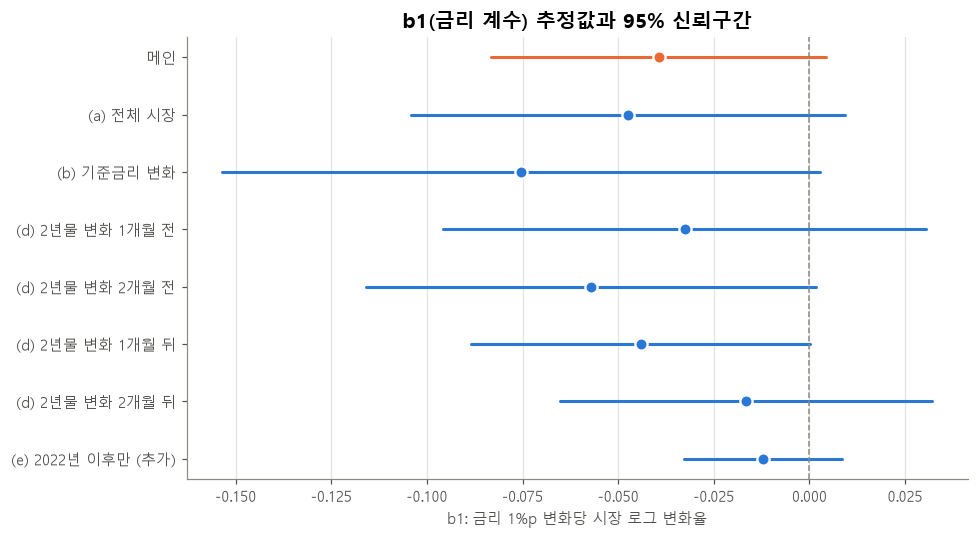

In [14]:
plot_rows = robust.drop(index="(c) 2년물 수준").iloc[::-1]   # 위에서부터 메인이 오도록 뒤집기
y_pos = np.arange(len(plot_rows))
is_main = plot_rows.index == "메인"

fig, ax = plt.subplots(figsize=(9, 5))
for y_i, (name, row) in zip(y_pos, plot_rows.iterrows()):
    color = COLORS[1] if name == "메인" else COLORS[0]
    ax.plot([row["95% 하한"], row["95% 상한"]], [y_i, y_i], color=color, linewidth=2, solid_capstyle="round")
    ax.plot(row["b1"], y_i, "o", color=color, markersize=8, markeredgecolor="white", markeredgewidth=1.5)

ax.axvline(0, color=MUTED, linestyle="--", linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_rows.index)
ax.grid(axis="y", visible=False)

ax.set_title("b1(금리 계수) 추정값과 95% 신뢰구간")
ax.set_xlabel("b1: 금리 1%p 변화당 시장 로그 변화율")
fig.tight_layout()
fig.savefig(FIG_DIR / "3_b1_robustness.png", dpi=200)
plt.show()

**읽는 법**
- **방향은 모든 검정에서 음수**다. "금리가 오르면 시장이 덜 크고, 내리면 더 큰다"는 방향은 설정을 바꿔도 유지된다.
- **크기는 꽤 흔들린다.** 대략 −0.08 ~ −0.01 사이이고, 대부분 신뢰구간이 0을 살짝 넘는다.
- (a) 전체 시장: 메인과 비슷하다(조금 더 음수). USDC를 빼는 선택이 결론을 바꾸지 않는다.
- (b) 기준금리: 계수가 더 크게 나온다(−0.075). 기준금리는 연준이 결정할 때만 움직여서 의미 있게 변한 달이 약 35%뿐이다(2년물은 약 68%). 두 금리의 월간 변화끼리 상관도 약 0.2로 낮다. 2년물이 기대를 먼저 반영하고 기준금리는 나중에 따라가기 때문이다. 그래서 두 계수의 크기를 그대로 비교하기는 어렵고, **방향이 같다**는 것이 핵심이다.
- (c) 수준: 유일하게 뚜렷이 유의하고 R²도 크다. 하지만 이건 "2020~21년 금리가 0이던 때 = 시장 급성장기"라는 **한 시기**가 만든 결과일 가능성이 크다. 금리가 낮았던 것 말고도 그때는 코인 붐이었다.
- (d) 시차: 2개월 전 변화(−0.057)와 1개월 뒤 변화(−0.044)도 같은 방향이다. 효과가 한 달에 몰리지 않고 **몇 달에 걸쳐 나타날** 수 있다는 신호다. 2개월 뒤는 거의 0이다.
- **(e) 2022년 이후만 쓰면 b1이 약 −0.012로 작아진다.** 메인 추정값의 상당 부분이 "급성장기가 끝나고 금리 인상이 시작된 2022년 초" 전환기에서 나온다는 뜻이다. 최근 시장에서는 관계가 더 약할 수 있다.

## 8. 잔차 확인: 이상한 달이 있나?

### 잔차 그래프
이 셀이 하는 일: 메인 회귀의 잔차(실제 − 예측)를 월별 막대로 그린다. 점선은 ±2 표준편차다. 이 선을 넘는 달은 **식이 설명하지 못한 큰 움직임**이 있었던 달이라 이름을 붙인다.

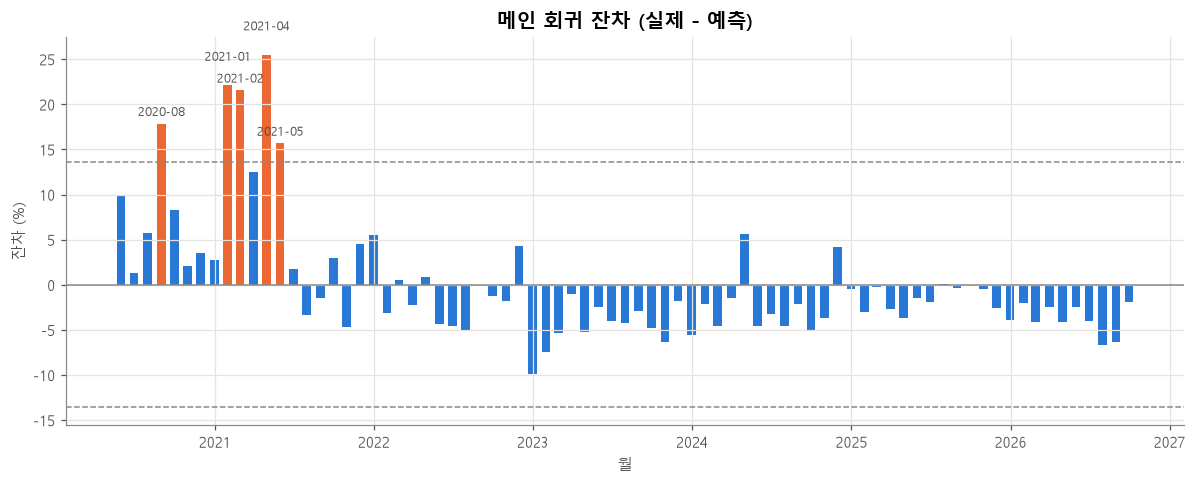

In [15]:
resid = main.resid * 100                 # % 단위로
resid_sd = resid.std()
outlier = resid.abs() > 2 * resid_sd

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(resid.index, resid.values, width=20,
       color=[COLORS[1] if o else COLORS[0] for o in outlier])
for sign in (1, -1):
    ax.axhline(sign * 2 * resid_sd, color=MUTED, linestyle="--", linewidth=1)
ax.axhline(0, color=MUTED, linewidth=1)
for i, (date, value) in enumerate(resid[outlier].items()):
    ax.annotate(f"{date:%Y-%m}", (date, value), xytext=(0, 5 + 11 * (i % 2)),   # 이웃 이름이 겹치지 않게 높이 번갈아
                textcoords="offset points", ha="center", fontsize=8, color=TEXT_SUB)

ax.set_title("메인 회귀 잔차 (실제 - 예측)")
ax.set_xlabel("월")
ax.set_ylabel("잔차 (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "3_residuals.png", dpi=200)
plt.show()

### 큰 잔차가 나온 달
이 셀이 하는 일: ±2 표준편차를 넘은 달의 실제 값, 예측 값, 잔차, 그리고 그달의 금리·비트코인 변화를 표로 본다.

In [16]:
outlier_table = pd.DataFrame({
    "실제(%)":        data.loc[outlier.index, "y_ex_usdc"] * 100,
    "예측(%)":        main.fittedvalues * 100,
    "잔차(%)":        resid,
    "2년물 변화(%p)":  data["d_dgs2"],
    "비트코인 변화(%)": data["d_log_btc"] * 100,
}).loc[outlier]
outlier_table

,실제(%),예측(%),잔차(%),2년물 변화(%p),비트코인 변화(%)
date,,,,,
2020-08-31,22.6659,4.8060,17.8600,-0.0106,2.5452
2021-01-31,28.0869,5.9685,22.1184,-0.0048,13.0585
2021-02-28,29.6630,8.0982,21.5648,-0.0157,31.5650
2021-04-30,29.6703,4.1746,25.4957,0.0179,-2.0563
2021-05-31,15.2396,-0.4349,15.6745,-0.0101,-43.9156


**읽는 법**
- 큰 잔차는 **모두 2020~21년**이고 모두 **양수**다. 식이 예측한 것보다 시장이 훨씬 빨리 컸다는 뜻이다. 그때는 금리가 0에 고정돼 있었으므로 금리로는 설명이 안 되고, 비트코인 변화만으로도 다 설명이 안 되는 **스테이블코인 급성장기**였다.
- 2022년 이후에는 ±2 표준편차를 넘는 달이 없다. 이벤트 더미가 큰 충격을 잘 흡수하고 있다.
- 대신 **2023년 이후 잔차가 대부분 음수**다. 식이 최근 달들을 **계속 과대 예측**한다는 뜻이다. 급성장기 때문에 상수 a(월 약 4.5%)가 커졌고, 최근 시장에는 너무 높은 기본 성장률이 깔려 있는 것이다. a는 **연 70%에 가까운 성장률이라 시뮬레이션에 그대로 쓰면 안 된다.** 6단계에서는 최근 기간의 성장률을 따로 정해야 한다.
- 이 패턴은 2020~21년과 그 이후의 **성격이 다르다**는 신호이기도 하다. 7번의 (e) 2022년 이후 추정이 메인과 다르게 나온 것과 같은 이야기다.
- 잔차가 몇 달씩 같은 방향(양수)으로 이어진 것이 5번에서 본 **자기상관**의 정체다.

## 9. 시뮬레이션용 시나리오 제안

b1의 방향(음수)과 범위(신뢰구간 약 −0.083 ~ +0.004)를 근거로 세 가지 시나리오를 둔다.

| 시나리오 | b1 | 의미 | 근거 |
|---|---|---|---|
| ① **보수** | 0 | 금리가 내려도 R은 금리와 상관없이 움직인다 | 신뢰구간이 0을 포함한다. 상한(+0.004)도 사실상 0이다. 2022년 이후 추정(−0.012)도 0에 가깝다 |
| ② **기본** | −0.039 | 2년물 1%p 하락 → 시장 약 +4% | 메인 회귀 추정값 |
| ③ **낙관** | −0.083 | 2년물 1%p 하락 → 시장 약 +9% | 95% 하한. 금리와 R의 반대 움직임이 가장 강한 경우 |

**왜 이 세 개인가?** 신뢰구간의 위쪽 끝은 0과 거의 같아서 ①이 그 역할을 겸한다. 그래서 세 시나리오가 **신뢰구간 전체를 덮는다.**

### 발행사 입장에서 무슨 차이인가
이 셀이 하는 일: "앞으로 3년간 2년물이 2%p 내리고, 준비금 수익률도 4% → 2%로 내린다"는 예시에서, 시나리오별로 시장(R)과 이익(r × R)이 얼마나 변하는지 계산한다.
- USDC 점유율은 그대로라고 가정한다(R의 변화율 = 시장 변화율).
- 간단한 예시라서 고정비 C와 다른 요인(비트코인, 추세)은 빼고 **금리 효과만** 본다.

In [17]:
SCENARIOS = {"① 보수": 0.0, "② 기본": b1, "③ 낙관": b1_low}
DGS2_CHANGE = -2.0             # 3년간 2년물 누적 변화 (%p)
R_YIELD_OLD, R_YIELD_NEW = 4.0, 2.0   # 준비금 수익률 (%)

scenario_rows = {}
for name, b in SCENARIOS.items():
    market_ratio = np.exp(b * DGS2_CHANGE)                       # 시장(R)이 몇 배가 되나
    profit_ratio = (R_YIELD_NEW / R_YIELD_OLD) * market_ratio    # 이익(r × R)이 몇 배가 되나
    scenario_rows[name] = {
        "b1":                 b,
        "R 변화(%)":           (market_ratio - 1) * 100,
        "이자수익 r×R 변화(%)":  (profit_ratio - 1) * 100,
        "R이 메워 준 몫(%p)":    (profit_ratio - R_YIELD_NEW / R_YIELD_OLD) * 100,
    }
pd.DataFrame(scenario_rows).T

,b1,R 변화(%),이자수익 r×R 변화(%),R이 메워 준 몫(%p)
① 보수,0.0000,0.0000,-50.0000,0.0000
② 기본,-0.0394,8.2063,-45.8968,4.1032
③ 낙관,-0.0831,18.0877,-40.9562,9.0438


**읽는 법**
- 금리가 반으로 줄면 이자수익은 R이 그대로일 때 **−50%**다(①).
- R이 금리 반대로 움직여도(②, ③) 메워 주는 몫은 **약 4~9%p**에 그친다. 이자수익은 여전히 **−41 ~ −46%** 줄어든다.
- 즉 **"금리가 내리면 발행량이 늘어 자연스럽게 헤지된다"는 효과는 있더라도 작다.** 금리 하락 위험을 막으려면 여전히 플로어가 필요하다. 이건 세 시나리오 모두에서 같은 결론이다.

### 정리와 다음 단계를 위한 메모
- **최적 정책은 ① 보수(b1 = 0)로 정한다.** 손실확률 기준에서는 자연 헤지를 기대하지 않는 쪽이 가장 보수적이다. 통계적으로도 배제되지 않고, 최근 기간 추정과도 가깝다. ② 기본과 ③ 낙관은 "자연 헤지가 있다면 플로어를 얼마나 덜 사도 되나"를 보는 민감도 분석으로 쓴다.
- **b1은 '그 달' 효과다.** 시뮬레이션에서는 매달 Δlog(R) = b1 × Δ(2년물)을 더해 가면 된다. 시차 검정에서 앞뒤 달에도 같은 방향의 효과가 보였으므로, 누적 효과는 이보다 조금 클 수 있다.
- **시뮬레이션의 금리 모형은 단기금리를 만든다.** 2년물 변화는 금리 모형(Vasicek·Hull-White)에서 단기금리로부터 계산할 수 있다(2년물 ≈ 단기금리의 함수).
- **상수 a(월 4.5%)는 쓰지 않는다.** 2020~21년 급성장기의 흔적이라 미래 추세로 쓰기에는 너무 크다.
- **USDC 점유율은 고정으로 가정했다.** SVB 같은 USDC 고유 충격은 점유율을 통해 R을 따로 흔들 수 있으므로, 시뮬레이션에서 별도 위험 요인으로 둘지 정해야 한다.

## 10. 자연 헤지 크기 (3년 경로 기준)

9번 계산은 "3년 뒤 한 시점"만 봤다. 실제 발행사의 이익은 3년 동안 **매달 쌓이는** 이자수익의 합이다. 그래서 금리가 서서히 내려가는 경로를 따라 3년 총 이자수익을 계산한다.

**가정**
- 3년(36개월) 동안 2년물이 **매달 같은 폭으로** 총 2%p 내린다.
- 준비금 수익률도 매달 같은 폭으로 **4% → 2%** 내린다.
- 시장(=R)은 매달 b1 × Δ(2년물)만큼 변한다. 금리 효과만 보려고 성장률 g와 고유 충격은 뺀다.
- 처음 R = 100 (단위는 상관없음). 이번 달 이자수익 = R × 이번 달 금리 ÷ 12

**비교 기준**: 금리가 3년 내내 4%이고 R도 100 그대로라면 3년 총 이자수익은 100 × 4% × 3 = **12**다.

이 셀이 하는 일: 세 b1 시나리오별로 3년 뒤 시장 증가율과 3년 총 이자수익(및 기준 대비 변화)을 계산한다.

In [18]:
MONTHS = 36
dgs2_path = np.linspace(0, -2.0, MONTHS + 1)[1:]        # 2년물 누적 변화: 매달 −2/36 %p씩
rate_path = np.linspace(4.0, 2.0, MONTHS + 1)[1:]       # 준비금 수익률: 4% → 2%
R0 = 100
BASE_TOTAL = R0 * 0.04 * 3                               # 금리 4% 유지 시 3년 총 이자수익 = 12

hedge_rows = {}
for name, b in SCENARIOS.items():
    R_path = R0 * np.exp(b * dgs2_path)                  # 매달 R
    income_total = np.sum(R_path * rate_path / 100 / 12)  # 3년 총 이자수익
    hedge_rows[name] = {
        "b1":                     b,
        "3년 뒤 시장 증가율(%)":      (R_path[-1] / R0 - 1) * 100,
        "3년 총 이자수익":            income_total,
        "금리 4% 유지 대비 변화(%)":   (income_total / BASE_TOTAL - 1) * 100,
    }
hedge = pd.DataFrame(hedge_rows).T
hedge["보수 대비 더 번 몫(%p)"] = hedge["금리 4% 유지 대비 변화(%)"] - hedge.loc["① 보수", "금리 4% 유지 대비 변화(%)"]
hedge

,b1,3년 뒤 시장 증가율(%),3년 총 이자수익,금리 4% 유지 대비 변화(%),보수 대비 더 번 몫(%p)
① 보수,0.0000,0.0000,8.9167,-25.6944,0.0000
② 기본,-0.0394,8.2063,9.2468,-22.9429,2.7515
③ 낙관,-0.0831,18.0877,9.6326,-19.7282,5.9663


**읽는 법**
- ① 보수: R이 그대로라서 금리 하락이 고스란히 이자수익 감소로 이어진다. 3년 총 이자수익이 12 → 약 8.9로, 기준 대비 약 **−26%**다.
- ② 기본, ③ 낙관: R이 3년 뒤 각각 약 +8%, +18% 커진다. 하지만 R은 **천천히** 늘고 금리는 처음부터 내리기 때문에, 3년 합계로 메워 주는 몫은 보수 대비 약 **+2.8%p, +6.0%p**에 그친다. 3년 뒤 한 시점만 본 9번 계산(4%p, 9%p)보다도 작다.
- **결론**: 자연 헤지는 있어도 이자수익 감소의 일부만 메운다. 9번의 한 시점 계산과 같은 결론이다.